# Student Performance Prediction System

## Day 02 – Exploratory Data Analysis (EDA)

### Objective

The objective of this analysis is to explore
student academic data, identify patterns,
understand feature distributions, and investigate
relationships between different variables
and final mathematics grades (G3).

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv("../dataset/student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (395, 33)


## 1. Feature Type Identification

Identify numerical and categorical columns
to understand the structure of the dataset.

In [2]:
# Identify numerical columns
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:", len(numerical_features))
print(numerical_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numerical Features: 16
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical Features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\vikra\AppData\Local\Temp\ipykernel_33868\2228799877.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(


In [3]:
# Verify feature counts
print("Total Features:", len(numerical_features) + len(categorical_features))
print("Total Dataset Columns:", df.shape[1])

Total Features: 33
Total Dataset Columns: 33


## 2. Numerical Feature Analysis

Visualize the distributions of numerical
variables using histograms.

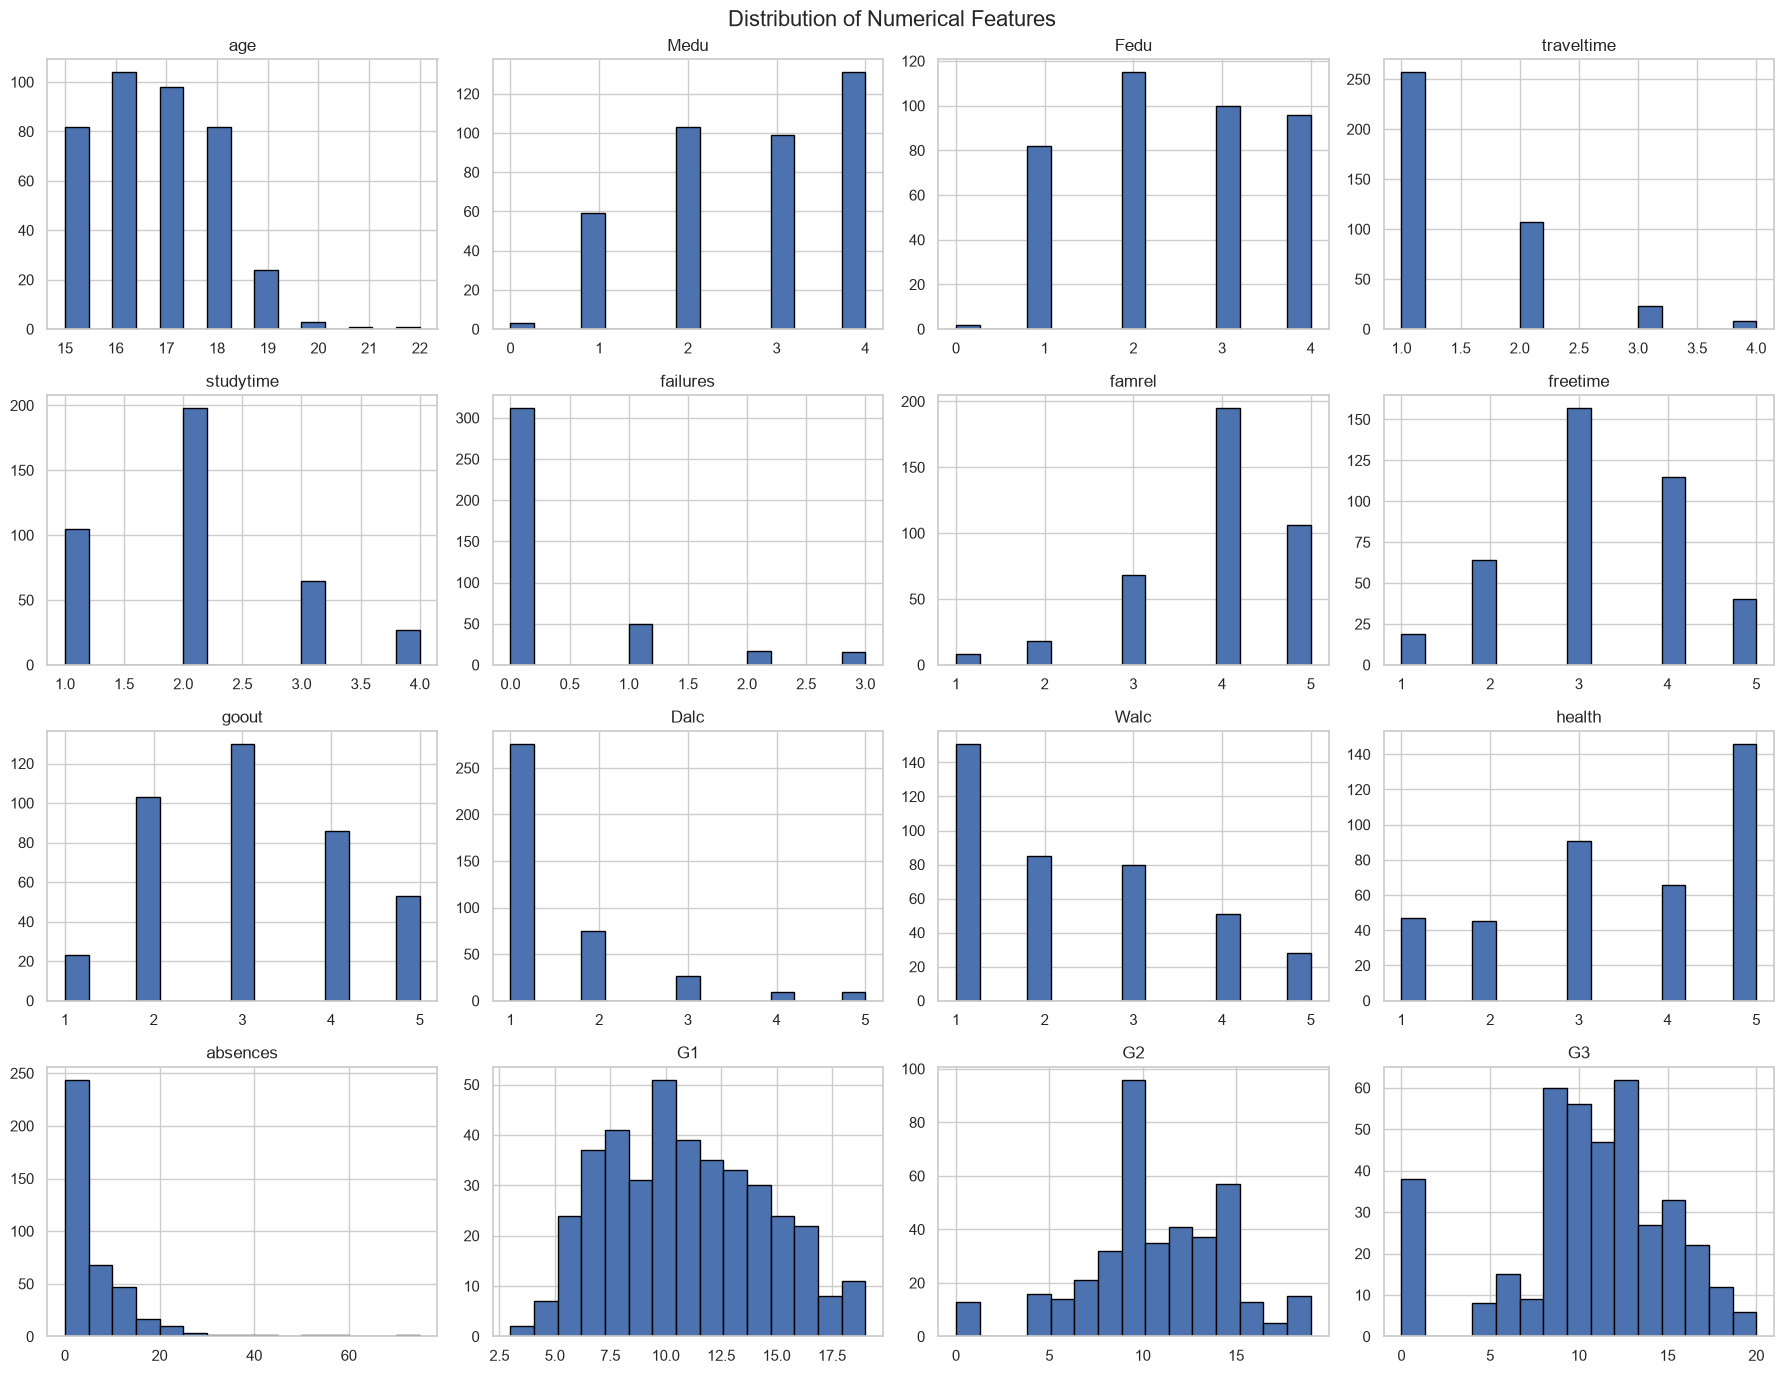

In [4]:
df[numerical_features].hist(
    figsize=(18, 14),
    bins=15,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 3. Target Variable Analysis

Analyze the distribution of the final grade (G3).

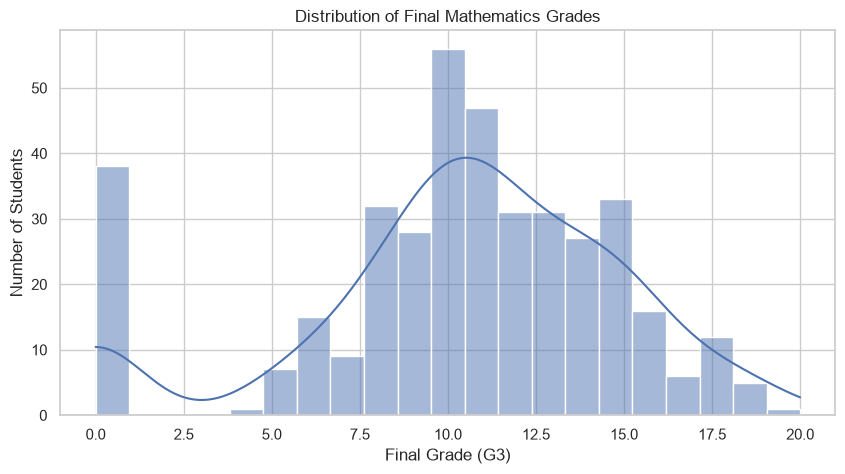

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="G3",
    bins=21,
    kde=True
)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()

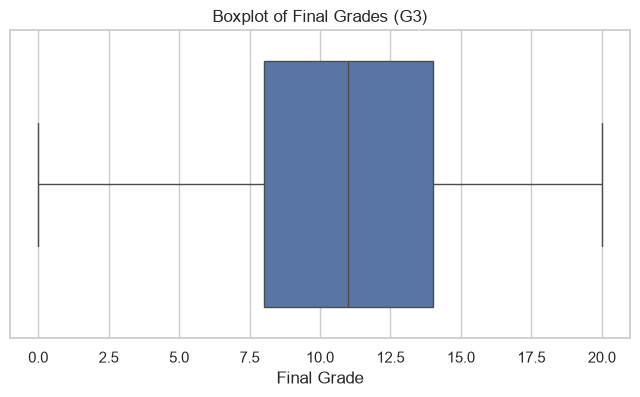

In [7]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["G3"])

plt.title("Boxplot of Final Grades (G3)")
plt.xlabel("Final Grade")

plt.show()

## 4. Correlation Analysis

Analyze the correlation between numerical features
to identify relationships and understand which
variables are associated with final student performance.

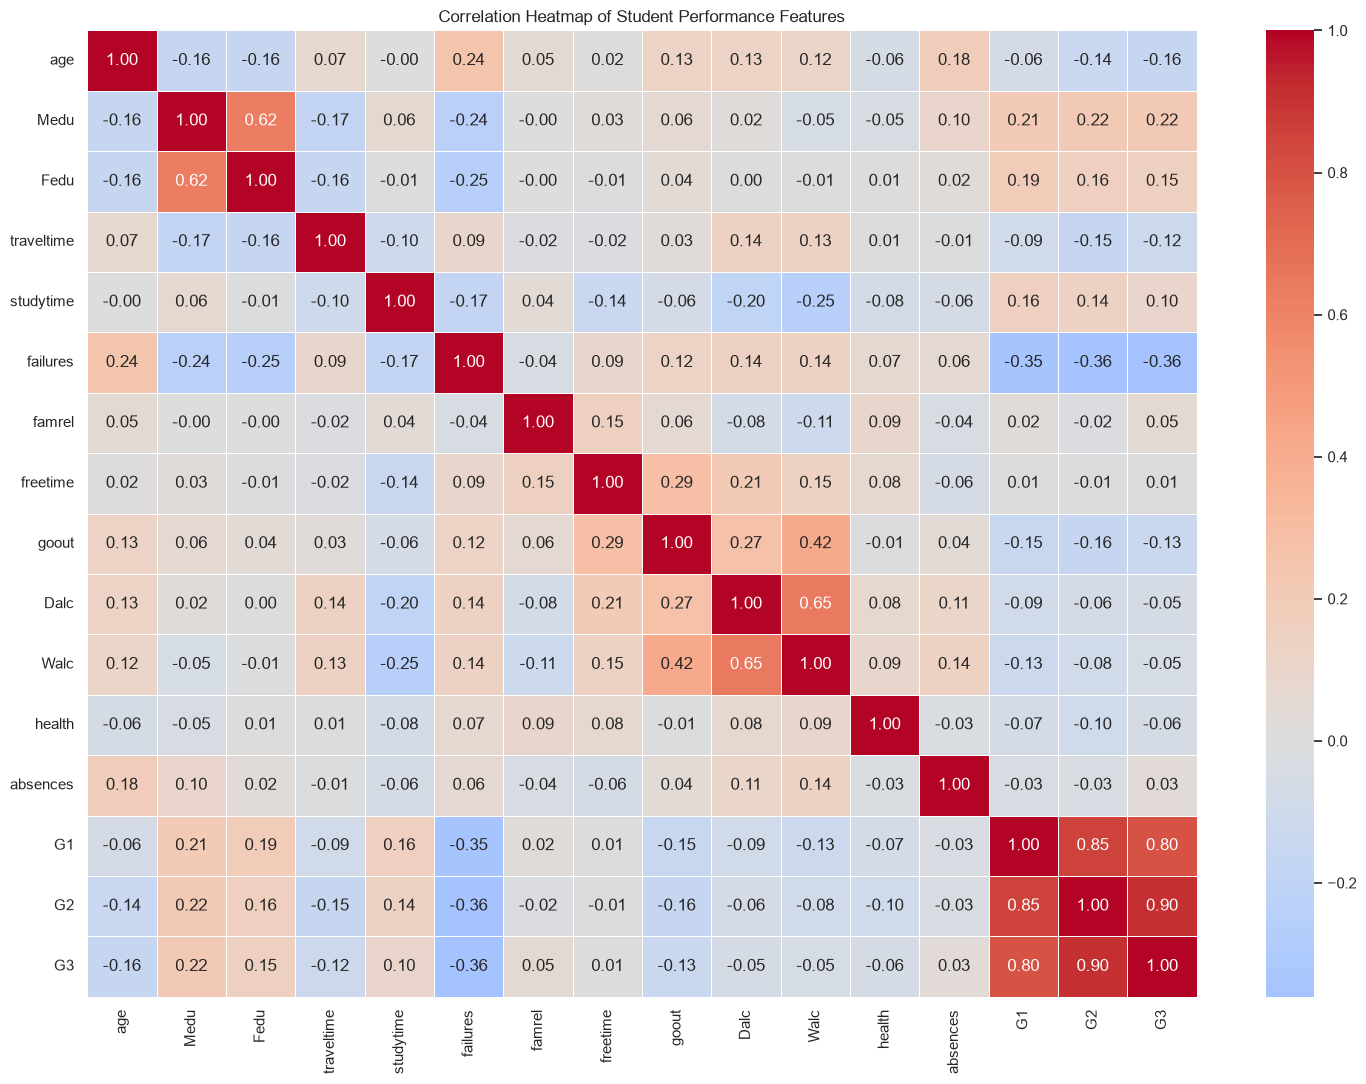

In [9]:

# Calculate correlation matrix
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Visualize correlation matrix
plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Student Performance Features")
plt.tight_layout()
plt.show()


In [10]:

# Identify features most correlated with final grade (G3)

g3_correlation = (
    correlation_matrix["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)

print("Correlation of Features with Final Grade (G3):")
display(g3_correlation)


Correlation of Features with Final Grade (G3):


G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


Analysis of sex


,mean,count
sex,,
M,10.91,187
F,9.97,208


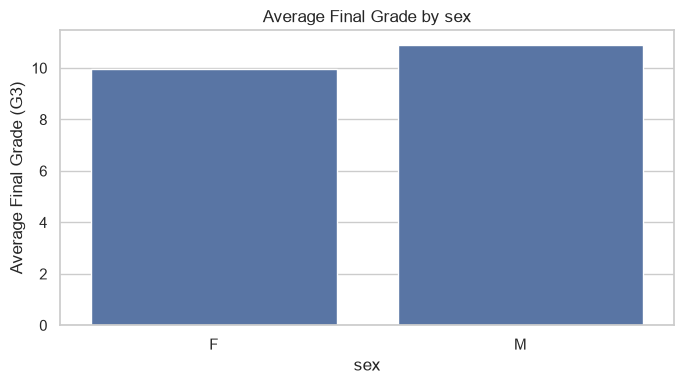


Analysis of address


,mean,count
address,,
U,10.67,307
R,9.51,88


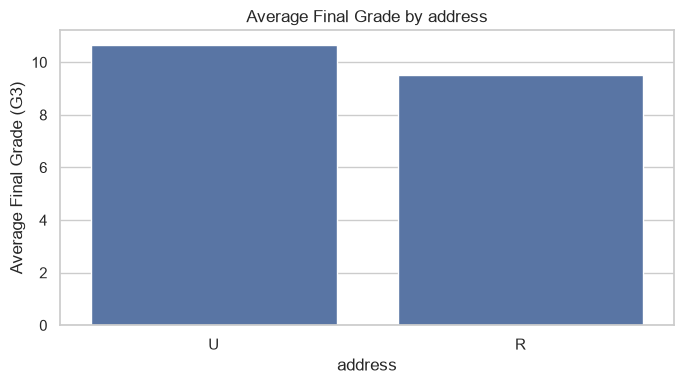


Analysis of famsize


,mean,count
famsize,,
LE3,11.00,114
GT3,10.18,281


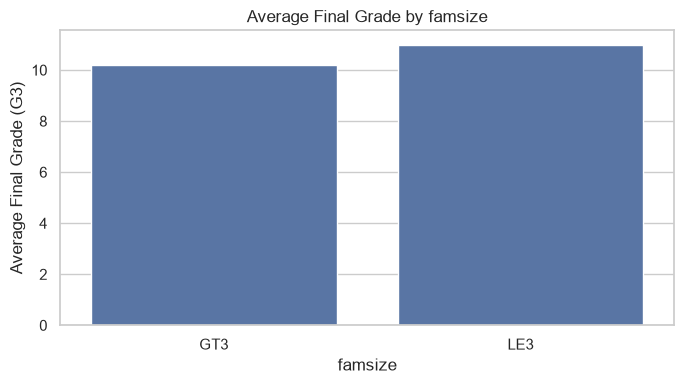


Analysis of Pstatus


,mean,count
Pstatus,,
A,11.20,41
T,10.32,354


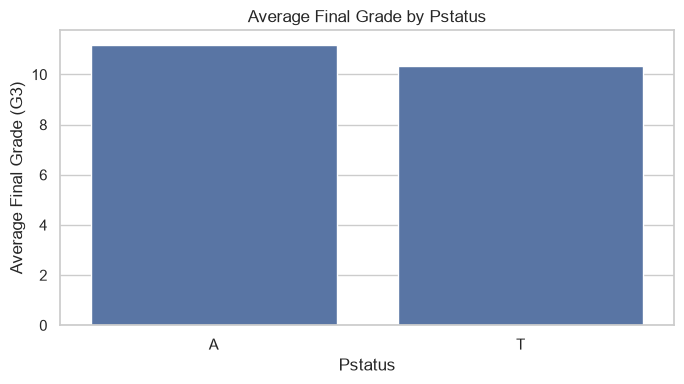


Analysis of schoolsup


,mean,count
schoolsup,,
no,10.56,344
yes,9.43,51


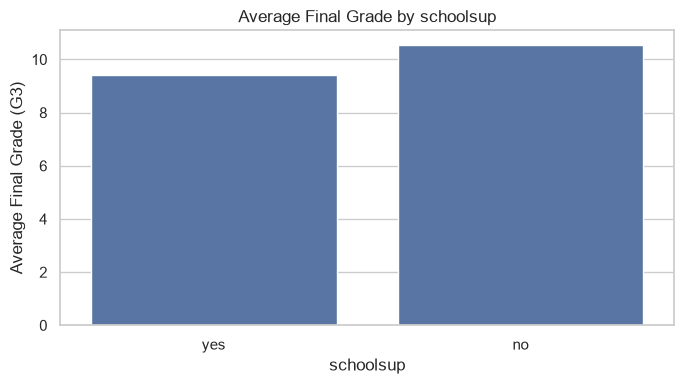


Analysis of famsup


,mean,count
famsup,,
no,10.64,153
yes,10.27,242


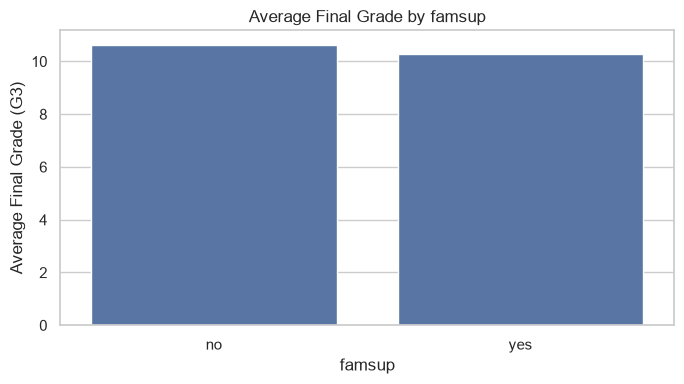


Analysis of paid


,mean,count
paid,,
yes,10.92,181
no,9.99,214


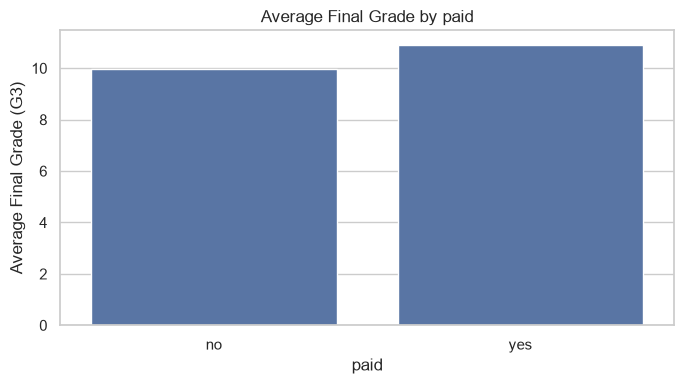


Analysis of activities


,mean,count
activities,,
yes,10.49,201
no,10.34,194


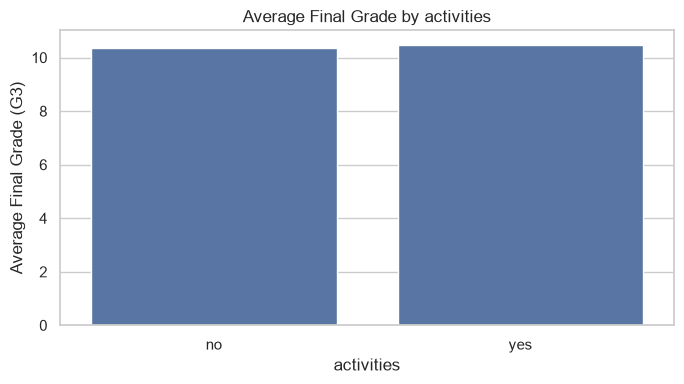


Analysis of nursery


,mean,count
nursery,,
yes,10.54,314
no,9.95,81


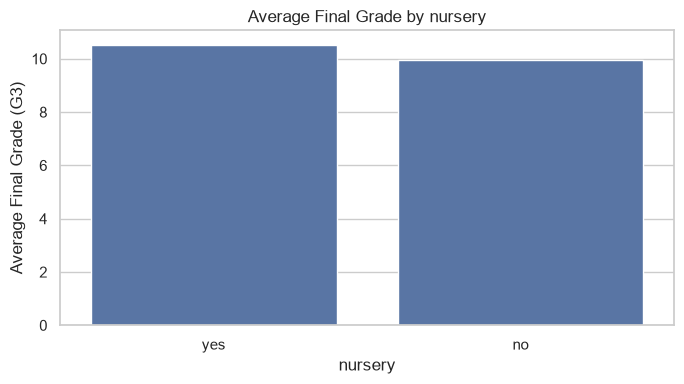


Analysis of higher


,mean,count
higher,,
yes,10.61,375
no,6.80,20


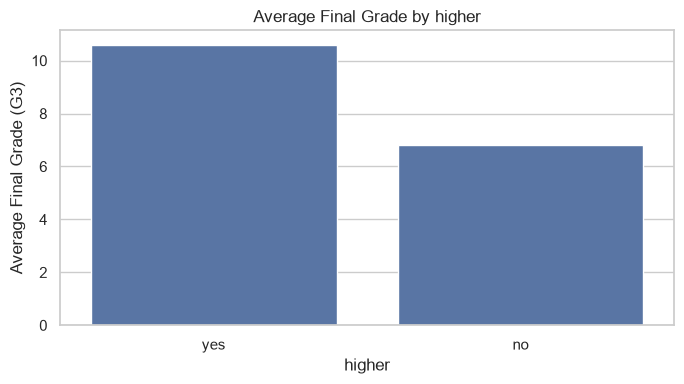


Analysis of internet


,mean,count
internet,,
yes,10.62,329
no,9.41,66


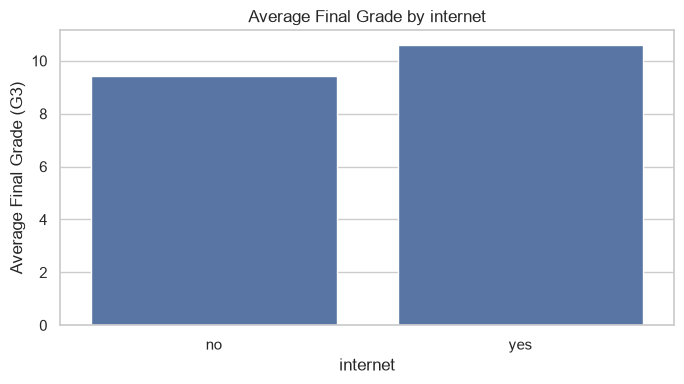


Analysis of romantic


,mean,count
romantic,,
no,10.84,263
yes,9.58,132


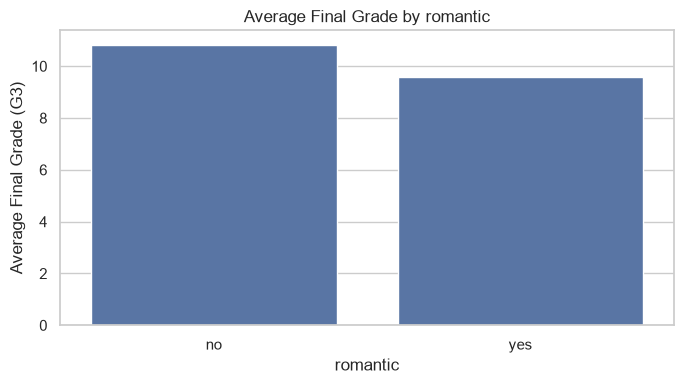

In [11]:
# Categorical Feature Analysis

categorical_cols = [
    'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

# Calculate average final grade for each category
for col in categorical_cols:

    print(f"\nAnalysis of {col}")

    result = (
        df.groupby(col)['G3']
        .agg(['mean', 'count'])
        .round(2)
        .sort_values('mean', ascending=False)
    )

    display(result)

    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=df,
        x=col,
        y='G3',
        errorbar=None
    )

    plt.title(f"Average Final Grade by {col}")
    plt.xlabel(col)
    plt.ylabel("Average Final Grade (G3)")
    plt.tight_layout()
    plt.show()

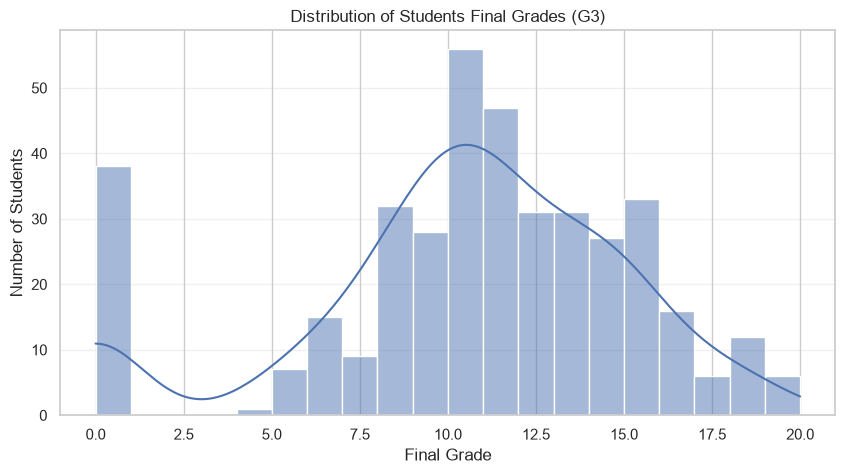

Final Grade Statistics:


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

In [12]:
# Distribution of Final Grades (G3)

plt.figure(figsize=(10, 5))

sns.histplot(
    df['G3'],
    bins=20,
    kde=True
)

plt.title('Distribution of Students Final Grades (G3)')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')
plt.grid(axis='y', alpha=0.3)

plt.show()

# Statistical summary
print("Final Grade Statistics:")
display(df['G3'].describe())

Student Performance Distribution:


performance
Average    192
Low        130
High        73
Name: count, dtype: int64

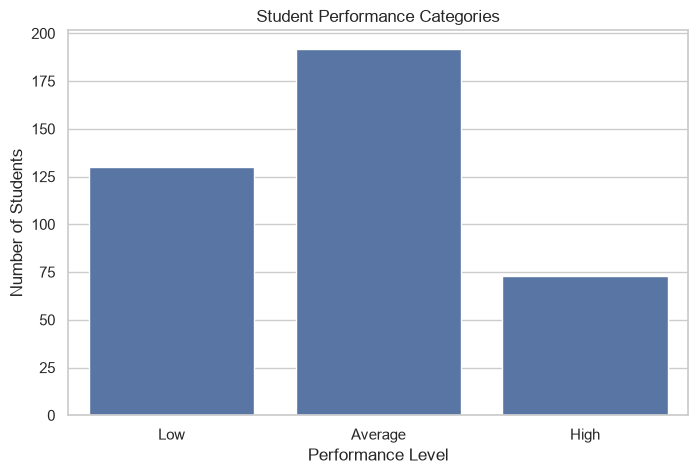

In [13]:
# Grade distribution by performance category

df['performance'] = pd.cut(
    df['G3'],
    bins=[-1, 9, 14, 20],
    labels=['Low', 'Average', 'High']
)

print("Student Performance Distribution:")
display(df['performance'].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='performance',
    order=['Low', 'Average', 'High']
)

plt.title('Student Performance Categories')
plt.xlabel('Performance Level')
plt.ylabel('Number of Students')

plt.show()

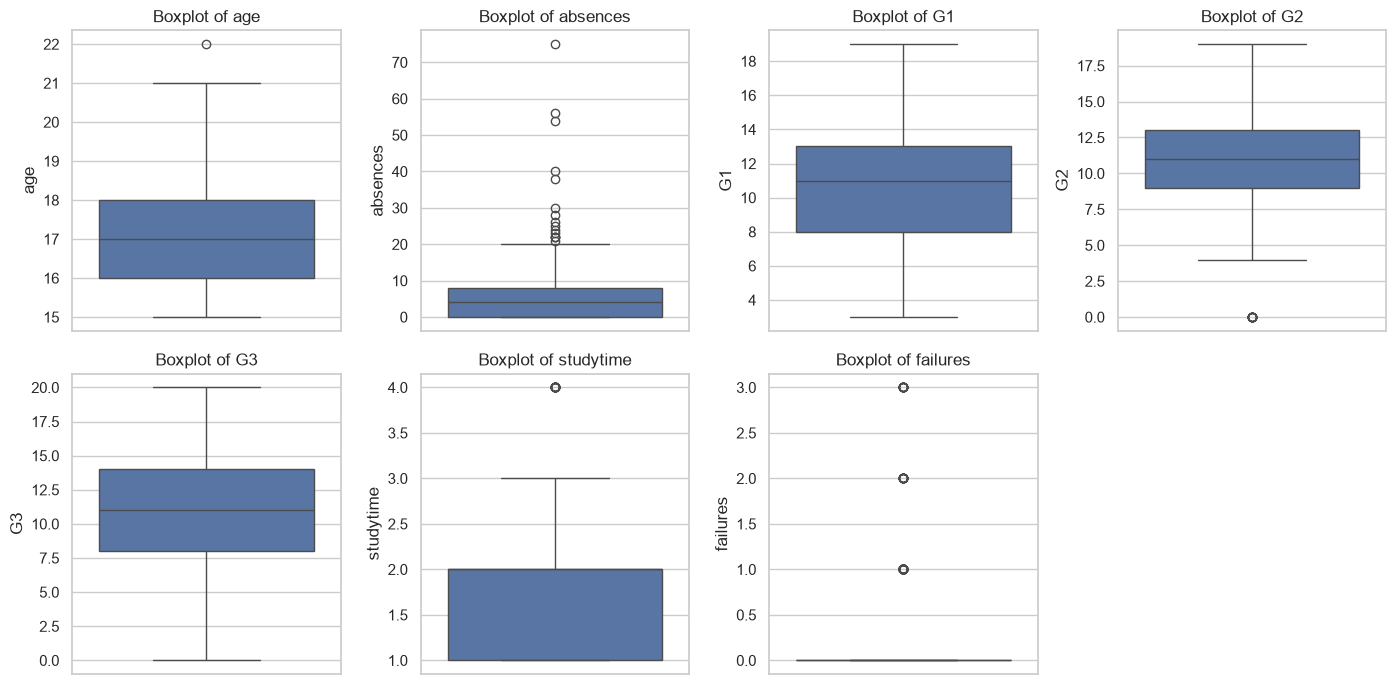

In [14]:
# Outlier Analysis using Boxplots

numerical_features = [
    'age', 'absences', 'G1', 'G2', 'G3',
    'studytime', 'failures'
]

plt.figure(figsize=(14, 7))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(2, 4, i)

    sns.boxplot(y=df[col])

    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [15]:
# Investigating students with zero final grades

zero_grades = df[df['G3'] == 0]

print("Students with zero final grades:", len(zero_grades))

print("\nPercentage of zero grades:")
print(round((len(zero_grades) / len(df)) * 100, 2), "%")

print("\nPrevious grades of students with G3 = 0:")

display(
    zero_grades[['G1', 'G2', 'G3', 'failures', 'absences']]
)

Students with zero final grades: 38

Percentage of zero grades:
9.62 %

Previous grades of students with G3 = 0:


,G1,G2,G3,failures,absences
128,7,4,0,2,0
130,12,0,0,2,0
131,8,0,0,0,0
134,9,0,0,0,0
135,11,0,0,0,0
136,10,0,0,0,0
137,4,0,0,2,0
140,7,9,0,0,0
144,5,0,0,3,0
146,6,7,0,3,0


In [16]:
# Detecting outliers using IQR

for col in numerical_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nFeature: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Feature: age
Lower Bound: 13.0
Upper Bound: 21.0
Number of Outliers: 1

Feature: absences
Lower Bound: -12.0
Upper Bound: 20.0
Number of Outliers: 15

Feature: G1
Lower Bound: 0.5
Upper Bound: 20.5
Number of Outliers: 0

Feature: G2
Lower Bound: 3.0
Upper Bound: 19.0
Number of Outliers: 13

Feature: G3
Lower Bound: -1.0
Upper Bound: 23.0
Number of Outliers: 0

Feature: studytime
Lower Bound: -0.5
Upper Bound: 3.5
Number of Outliers: 27

Feature: failures
Lower Bound: 0.0
Upper Bound: 0.0
Number of Outliers: 83


In [17]:
categorical_features = [
    'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

for col in categorical_features:
    print(f"\nFeature: {col}")

    result = df.groupby(col)['G3'].agg(
        ['count', 'mean', 'median']
    )

    print(result)


Feature: sex
     count       mean  median
sex                          
F      208   9.966346    10.0
M      187  10.914439    11.0

Feature: address
         count       mean  median
address                          
R           88   9.511364    10.0
U          307  10.674267    11.0

Feature: famsize
         count       mean  median
famsize                          
GT3        281  10.177936    11.0
LE3        114  11.000000    11.0

Feature: Pstatus
         count       mean  median
Pstatus                          
A           41  11.195122    11.0
T          354  10.324859    11.0

Feature: schoolsup
           count       mean  median
schoolsup                          
no           344  10.561047    11.0
yes           51   9.431373    10.0

Feature: famsup
        count       mean  median
famsup                          
no        153  10.640523    11.0
yes       242  10.272727    11.0

Feature: paid
      count       mean  median
paid                          
no      214   

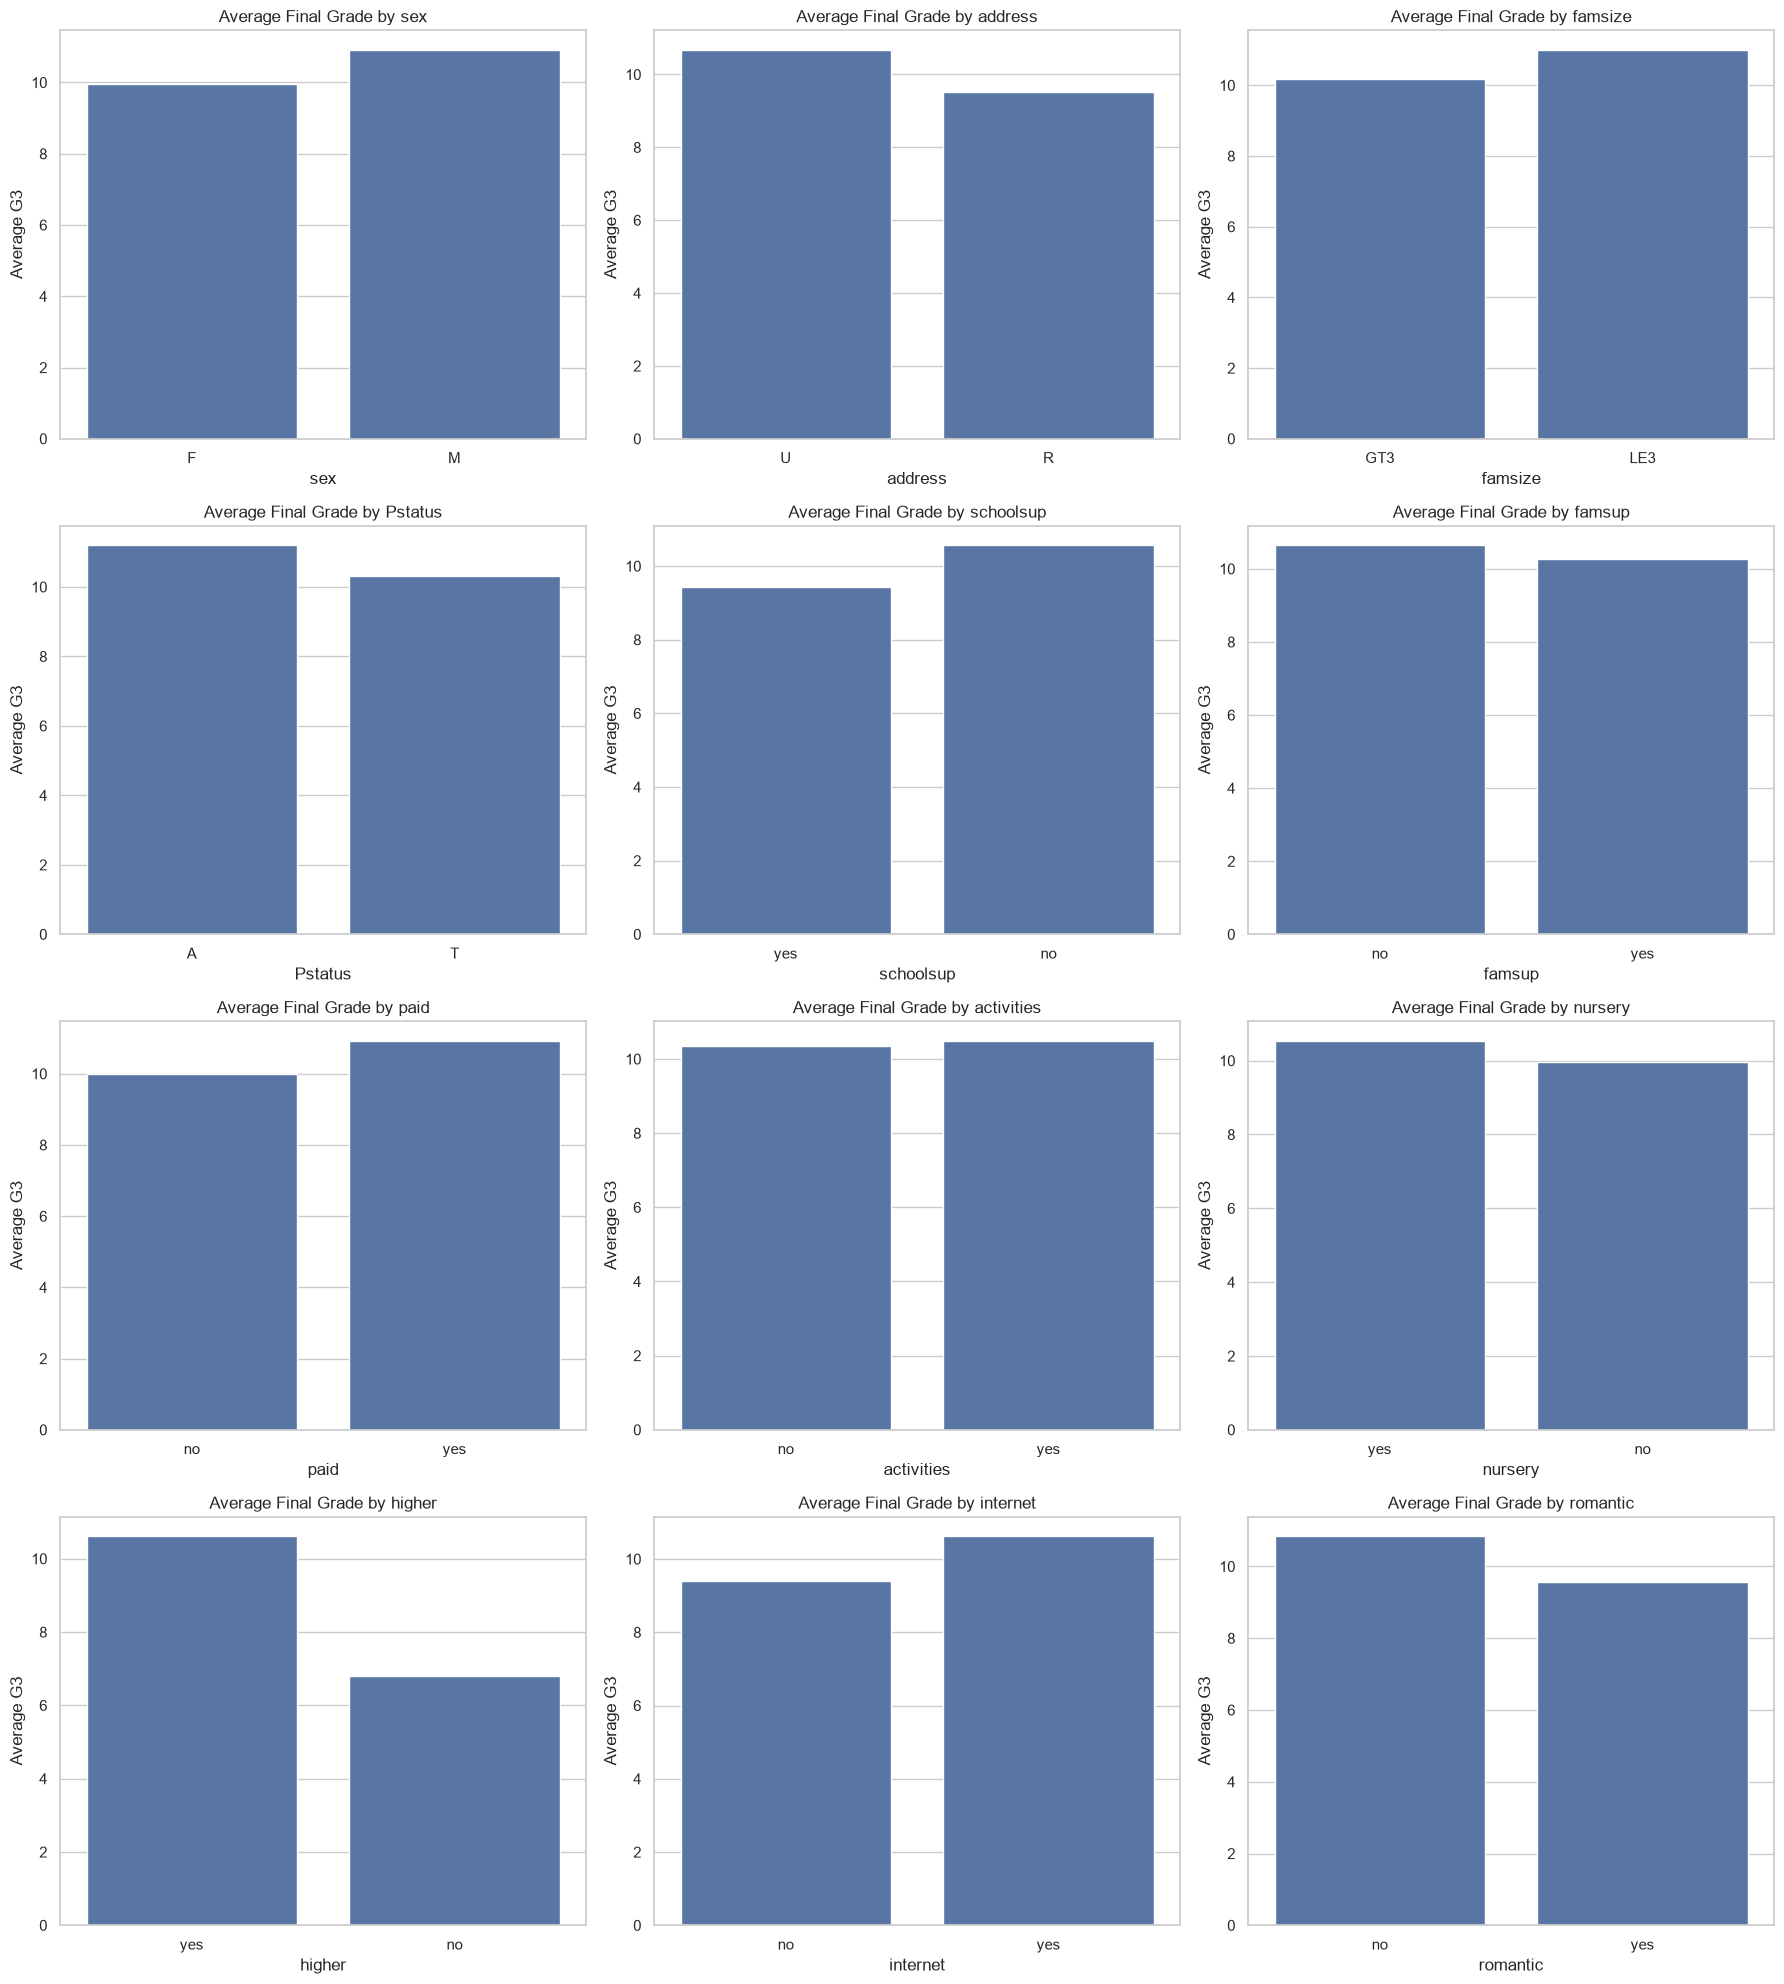

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 3, figsize=(18, 20))

for ax, col in zip(axes.flatten(), categorical_features):

    sns.barplot(
        data=df,
        x=col,
        y='G3',
        ax=ax,
        errorbar=None
    )

    ax.set_title(f'Average Final Grade by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Average G3')

plt.tight_layout()
plt.show()

Correlation of Features with Final Grade (G3):
G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


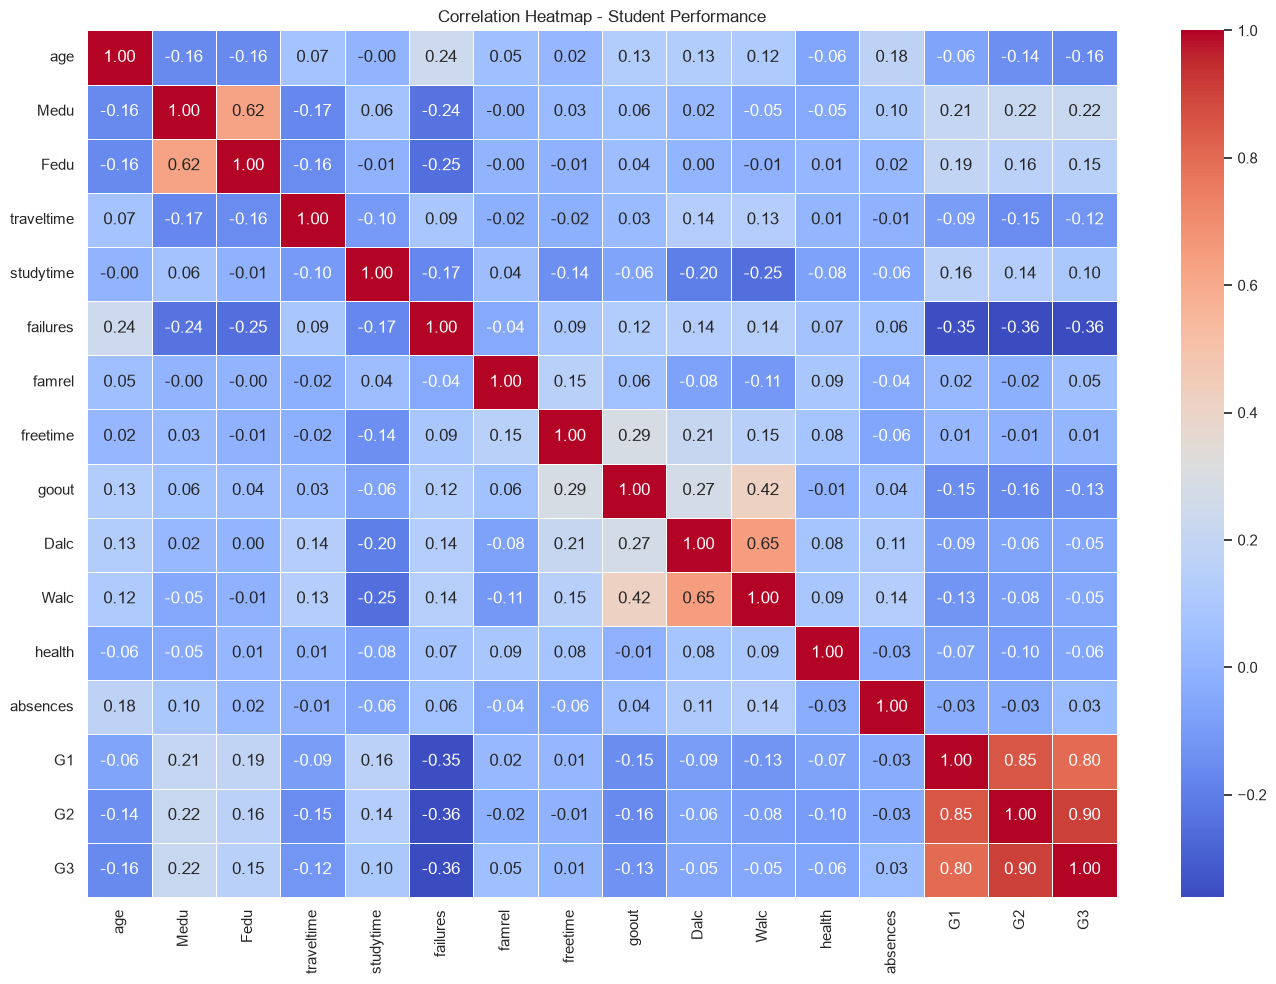

In [19]:

# Correlation Analysis

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Correlation with final grade
g3_correlation = correlation_matrix['G3'].sort_values(
    ascending=False
)

print("Correlation of Features with Final Grade (G3):")
print(g3_correlation)

# Visualize correlation matrix
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap - Student Performance')
plt.tight_layout()
plt.show()


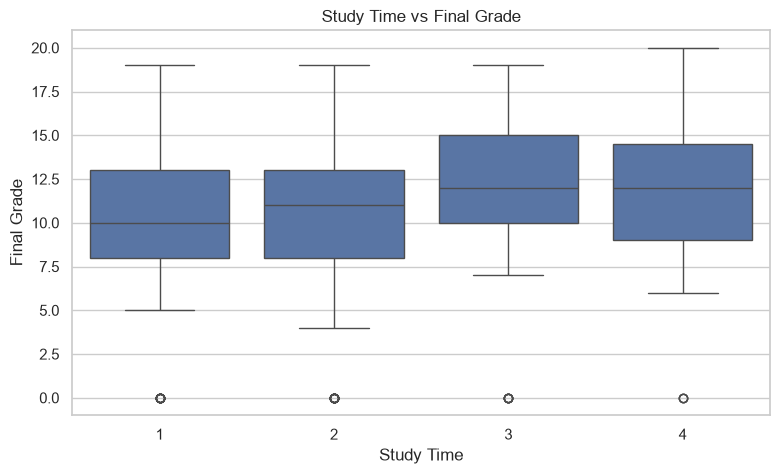

In [20]:
# Relationship between study time and final grades

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='studytime',
    y='G3'
)

plt.title('Study Time vs Final Grade')
plt.xlabel('Study Time')
plt.ylabel('Final Grade')

plt.show()

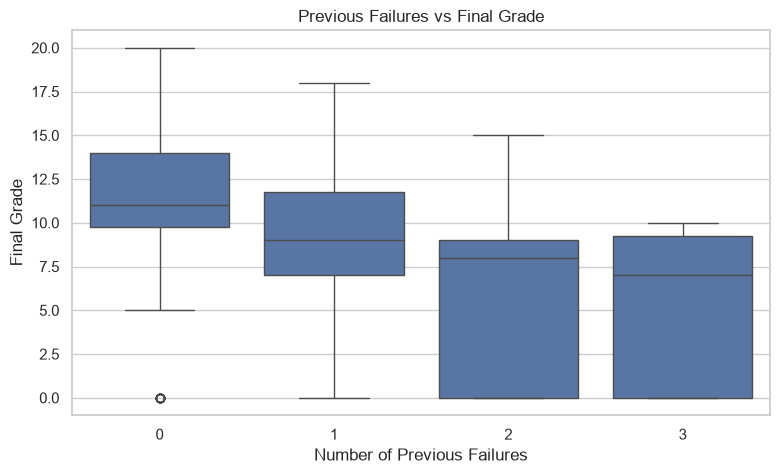

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='failures',
    y='G3'
)

plt.title('Previous Failures vs Final Grade')
plt.xlabel('Number of Previous Failures')
plt.ylabel('Final Grade')

plt.show()

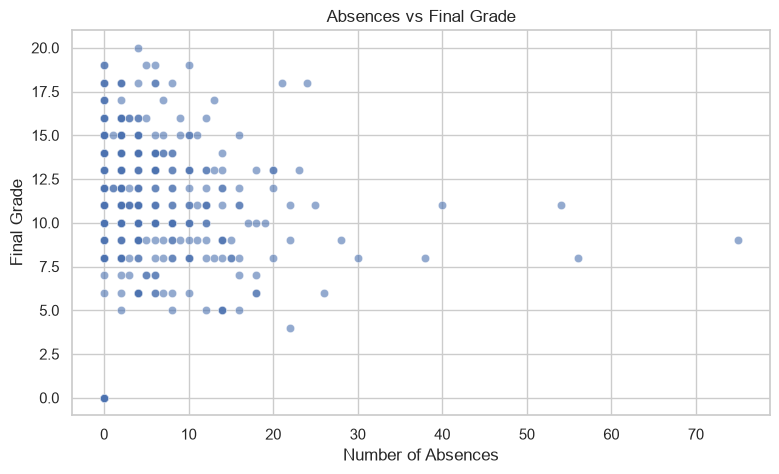

In [22]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='absences',
    y='G3',
    alpha=0.6
)

plt.title('Absences vs Final Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade')

plt.show()

##  Exploratory Data Analysis – Key Findings

### 1. Dataset Overview
The dataset contains 395 student records and 33 features related to demographic information, family background, academic performance, and social activities.

### 2. Target Variable Analysis
The final grade (G3) has a mean of approximately 10.42 and a median of 11. A total of 38 students (9.62%) received a final grade of zero.

### 3. Outlier Analysis
Outliers were identified in age, absences, G2, studytime, and failures. These observations were retained because they may represent genuine student characteristics or academic outcomes.

### 4. Categorical Feature Analysis
Students aspiring to pursue higher education showed higher average final grades. Differences were also observed across internet access, school support, paid classes, and other demographic categories.

### 5. Correlation Analysis
G1 (0.80) and G2 (0.90) showed the strongest positive correlations with G3. Previous failures showed a moderate negative correlation (-0.36).

### 6. Bivariate Analysis
Studytime showed a modest positive association with final grades. Students with more previous academic failures generally demonstrated lower final-grade distributions. Absences showed little linear correlation with final grades.

### 7. Conclusion
The EDA identified previous academic performance and academic failures as important indicators of student outcomes. These findings will guide feature selection, preprocessing, and subsequent predictive modelling.